# 03 — Results and robustness charts

**Goal:** compare the trained models and see how their scores drop when the photos are damaged
(blur, JPEG, downscale, noise, screen — see notebook 02).

**This notebook does not train anything.** It reads score files that notebook 05 (Step 9) or Step 1b below
saved, one per experiment:

```
outputs/<experiment>/eval_test.csv      e.g. outputs/03_effnet_finetune/eval_test.csv
```

Each row of that file is one test condition: `clean` (undamaged photos) or one kind of damage at severity 1–5.

**How to use:** this notebook runs on **Kaggle** or **Google Colab** (it detects which one by itself). Do the
settings below once, then run the cells from top to bottom (Shift+Enter). The images and a GPU are only needed
for Step 1b; the charts only need the score files.

### Before you start (Kaggle): settings

Open the right-hand panel of the notebook editor (the **>|** icon at the top right if it is hidden):

- **Settings → Internet → On.** Step 1 downloads the project code from GitHub. Kaggle asks you to verify your phone once.
- **Add Input → Datasets →** search **"140k Real and Fake Faces"** (by xhlulu) → **+**. These are the images.
  Kaggle attaches them read-only under `/kaggle/input/`, so nothing is downloaded or unzipped.
- **Add Input → Your Work → Notebooks →** your saved notebook 05 → **+**. This brings in its trained models
  (`outputs/<experiment>/best.pt`) and score files, read-only. Notebook 05 must be saved first with
  **Save Version → Save & Run All (Commit)**.
- Only for Step 1b (scoring models here): **Settings → Accelerator → GPU T4 x2.** Makes the model steps much faster (free, about 30 GPU hours a week).

After you change a setting, Kaggle restarts the session: run the cells again from the top.

### Before you start (Google Colab)

1. **Run notebook 01 on Colab once first.** It connects your Google Drive, saves the project code in
   `My Drive/deepfake_kyc/` and downloads the dataset zip there (it needs your Kaggle token for that). This notebook
   reuses both, so it does not download them again.
2. **Open this notebook:** colab.research.google.com → **File → Open notebook → GitHub**, paste
   `https://github.com/msondhi/UOT_SCS_3546_041_Deep-Learning` and pick `notebooks/03_results_charts.ipynb`.
   Colab warns *"This notebook was not authored by Google"*: it is this project's own code, so click **Run anyway**.
3. Run Step 1. Colab asks to connect your Google Drive: allow it (pick the same Google account and tick **Select all**).
4. **GPU (only for Step 1b):** **Runtime → Change runtime type → T4 GPU** (or the GPU your Colab plan offers).
5. **Trained models:** on Colab this notebook reads them from your Drive, in
   `My Drive/deepfake_kyc/UOT_SCS_3546_041_Deep-Learning/outputs/<experiment>/` (`best.pt`, `config.yaml`,
   `eval_test.csv`). **Notebook 05 on Colab saves them there by itself.** Only if you trained on Kaggle instead:
   open your saved notebook 05 on Kaggle → **Output** → download the experiment folders inside `outputs/` → upload
   them into that `outputs/` folder in your Drive, one folder per experiment (e.g. `outputs/03_effnet_finetune/best.pt`).

After **Runtime → Restart session** (or when Colab disconnects), every variable is forgotten: run the cells again
from Step 1.

## Step 1 — Get the project and find the score files

**What this does, in plain words:**

1. Loads the Python tools we need and checks whether it runs on Kaggle or Google Colab.
2. Gets the project code (`src/`, `configs/`):
   - **Kaggle:** downloads it from GitHub into `/kaggle/working/`, the only folder on Kaggle where we can write
     files. If Internet is off, it tells you so in plain words.
   - **Colab:** connects your Google Drive and uses the project in `My Drive/deepfake_kyc/` (the copy notebook 01
     saved there), updating it from GitHub first (`UPDATE_PROJECT`).
3. Finds the dataset (only Step 1b needs the test photos):
   - **Kaggle:** the one you attached with **Add Input**, somewhere under `/kaggle/input/`.
   - **Colab:** only if you set `GET_IMAGES = True`: then it unzips the images from the dataset zip in your Drive
     (about 2 minutes, once per session). Leave it `False` when you only want the charts.
4. Makes the list of folders to search for trained models and score files:
   - **Kaggle:** the `outputs/` folder of every notebook you attached with **Add Input → Your Work** (for example
     your saved notebook 05, read-only), and this notebook's own `outputs/` folder in `/kaggle/working/`.
   - **Colab:** the project's `outputs/` folder in your Drive.
5. Finds every `eval_*.csv` file in those folders. On Kaggle, if the same file is found twice, the copy in this
   notebook's own `outputs/` wins, because it is the newest.

In [1]:
# 1. Tools we need
import os
import shutil
import subprocess
import sys
import zipfile
from pathlib import Path

import matplotlib.pyplot as plt
import pandas as pd
import yaml
from IPython.display import display

REPO_URL = "https://github.com/msondhi/UOT_SCS_3546_041_Deep-Learning.git"
DATASET = "xhlulu/140k-real-and-fake-faces"     # the Kaggle dataset (about 4 GB zip)

# ---- Google Colab settings (ignored on Kaggle) -------------------------------------------
# Keep these the same as in notebook 01, so all notebooks share one project folder and one dataset zip in your Drive.
DRIVE_FOLDER = "deepfake_kyc"   # folder inside "My Drive" for the project, the dataset zip and the outputs
DATA_LOCATION = "local"         # "local" = unzip the images to Colab's fast local disk each session (about 2 min,
                                #           recommended; the zip itself stays on your Drive)
                                # "drive" = unzip once into your Drive (first time can take an hour; reading images
                                #           from Drive is much slower)
UPDATE_PROJECT = True           # True = get the latest project code from GitHub at the start (safe: never overwrites
                                #        your own changes, it just prints a message if it cannot update)
GET_IMAGES = False              # True = unzip the test photos too; only Step 1b (scoring models) needs them
# ------------------------------------------------------------------------------------------

ON_KAGGLE = Path("/kaggle/input").is_dir()
ON_COLAB = "google.colab" in sys.modules


def run(command):
    """Run a terminal command and return True if it worked."""
    return subprocess.run(command).returncode == 0


def find_dataset(search_roots):
    """Look inside the given folders for the folder called real-vs-fake that has train/ valid/ test/."""
    for root in search_roots:
        for depth in range(0, 5):                               # look 0, 1, 2, 3, then 4 folders deep
            pattern = "/".join(["*"] * depth + ["real-vs-fake"])  # e.g. "*/*/real-vs-fake"
            for folder in Path(root).glob(pattern):
                if (folder / "train").is_dir():
                    return folder
    return None


def get_kaggle_token(drive_home):
    """Kaggle token for downloading the dataset: Colab Secrets first, then kaggle.json in your Drive folder."""
    try:
        from google.colab import userdata
        os.environ["KAGGLE_USERNAME"] = userdata.get("KAGGLE_USERNAME")
        os.environ["KAGGLE_KEY"] = userdata.get("KAGGLE_KEY")
        return True
    except Exception:
        pass
    token = drive_home / "kaggle.json"
    if token.exists():
        kaggle_dir = Path.home() / ".kaggle"
        kaggle_dir.mkdir(exist_ok=True)
        (kaggle_dir / "kaggle.json").write_bytes(token.read_bytes())
        (kaggle_dir / "kaggle.json").chmod(0o600)
        return True
    return False


if ON_COLAB:
    # 2a. Connect your Google Drive (Colab asks you to allow it the first time).
    from google.colab import drive
    drive.mount("/content/drive")
    DRIVE_HOME = Path("/content/drive/MyDrive") / DRIVE_FOLDER
    DRIVE_HOME.mkdir(parents=True, exist_ok=True)

    # 2b. The project code lives in your Drive (notebook 01 put it there; if it is missing it is downloaded now),
    #     so it, and everything saved in its outputs/ folder, stays after the session ends.
    PROJECT_ROOT = DRIVE_HOME / "UOT_SCS_3546_041_Deep-Learning"
    if not (PROJECT_ROOT / "src").exists():
        print("Downloading the project code into your Drive ...")
        if not run(["git", "clone", "--depth", "1", REPO_URL, str(PROJECT_ROOT)]):
            raise RuntimeError("Could not download the project from GitHub. Check the internet connection and run again.")
    elif UPDATE_PROJECT:
        # Google Drive does not keep Linux file permissions; tell git not to count that as a change you made.
        run(["git", "-C", str(PROJECT_ROOT), "config", "core.fileMode", "false"])
        if not run(["git", "-C", str(PROJECT_ROOT), "pull", "--ff-only", "-q"]):
            print("Note: could not update the project code (you may have changed files in it). Using the copy in Drive.")

    # 3. The images: the dataset zip in your Drive is unzipped (it is downloaded from Kaggle first if it is missing).
    #    Colab's local disk is emptied when the session ends, so with DATA_LOCATION = "local" this runs once per session.
    DATASET_ZIP = DRIVE_HOME / "datasets" / "140k-real-and-fake-faces.zip"
    IMAGES_HOME = Path("/content/data") if DATA_LOCATION == "local" else DRIVE_HOME / "datasets" / "140k"
    UNZIP_DONE = IMAGES_HOME / ".unzip_complete"   # written only after a full unzip, so a cut-off unzip is redone
    if GET_IMAGES and not UNZIP_DONE.exists():
        if not DATASET_ZIP.exists():
            if not get_kaggle_token(DRIVE_HOME):
                raise RuntimeError(
                    "To download the dataset once, Colab needs your Kaggle API token. Either add Colab Secrets "
                    "KAGGLE_USERNAME and KAGGLE_KEY (key icon on the left, turn on 'Notebook access'), or put "
                    f"kaggle.json in your Drive folder: My Drive/{DRIVE_FOLDER}/kaggle.json. Then run this cell again.")
            print("Downloading the dataset zip into your Drive (about 4 GB, only the first time) ...")
            DATASET_ZIP.parent.mkdir(parents=True, exist_ok=True)
            if shutil.which("kaggle") is None:
                run([sys.executable, "-m", "pip", "install", "-q", "kaggle"])
            if not run(["kaggle", "datasets", "download", "-d", DATASET, "-p", str(DATASET_ZIP.parent)]):
                raise RuntimeError("Kaggle download failed. Check your Kaggle token, then run this cell again.")
        print(f"Unzipping the images to {IMAGES_HOME} (about 2 minutes) ...")
        IMAGES_HOME.mkdir(parents=True, exist_ok=True)
        try:
            with zipfile.ZipFile(DATASET_ZIP) as archive:
                images = [name for name in archive.namelist() if name.startswith("real_vs_fake/")] or archive.namelist()
                archive.extractall(IMAGES_HOME, members=images)
        except zipfile.BadZipFile:
            DATASET_ZIP.unlink()      # a broken zip (e.g. the download was cut off) would fail every time
            raise RuntimeError("The dataset zip in your Drive was broken (probably an interrupted download), so it "
                               "was deleted. Run this cell again to download it again.")
        UNZIP_DONE.touch()            # mark the unzip as complete
        print(f"Unzipped {len(images):,} files.")
    SEARCH_ROOTS = [IMAGES_HOME]

    # 4. Trained models and score files: the project's outputs/ folder in your Drive
    #    (notebook 05 on Colab saves them there; see "Before you start (Google Colab)").
    RESULTS_FOLDERS = [PROJECT_ROOT / "outputs"]

elif ON_KAGGLE:
    # 2. Get the project code (src/ and configs/) from GitHub into /kaggle/working,
    #    the only folder on Kaggle where we can write files.
    PROJECT_ROOT = Path("/kaggle/working/UOT_SCS_3546_041_Deep-Learning")
    if not PROJECT_ROOT.exists():
        if not run(["git", "clone", "--depth", "1", REPO_URL, str(PROJECT_ROOT)]):
            raise RuntimeError("Could not download the project from GitHub. "
                               "Turn on Settings -> Internet in the right-hand panel, then run this cell again.")
    # 3. The dataset you attached with Add Input is somewhere under /kaggle/input.
    SEARCH_ROOTS = [Path("/kaggle/input")]

    # 4. Folders to search for trained models and scores:
    #  - outputs/ of other notebooks you attached with Add Input -> Your Work (read-only),
    #    e.g. your saved notebook 05: /kaggle/input/<notebook>/.../outputs/
    #  - this notebook's own outputs/ in /kaggle/working (listed last, so a new file made here wins)
    RESULTS_FOLDERS = []
    for depth in range(1, 5):
        RESULTS_FOLDERS += sorted(Path("/kaggle/input").glob("/".join(["*"] * depth) + "/outputs"))
    RESULTS_FOLDERS.append(PROJECT_ROOT / "outputs")

else:
    # On your own computer: use the project folder this notebook is in, and its data/raw folder.
    PROJECT_ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "deepfake_kyc").is_dir())
    SEARCH_ROOTS = [PROJECT_ROOT / "data" / "raw"]
    RESULTS_FOLDERS = [PROJECT_ROOT / "outputs"]

sys.path.insert(0, str(PROJECT_ROOT / "src"))   # lets Python import the project's own code
print("Running on:    ", "Google Colab" if ON_COLAB else "Kaggle" if ON_KAGGLE else "this computer")
print("Project folder:", PROJECT_ROOT)

DATA_ROOT = find_dataset(SEARCH_ROOTS)   # folder with train/ valid/ test/, or None if not found
if DATA_ROOT is None:
    print('No test photos loaded: fine for the charts; only Step 1b needs them (Kaggle: Add Input -> Datasets -> '
          '"140k Real and Fake Faces"; Colab: set GET_IMAGES = True and run this cell again).')
else:
    print("Images folder: ", DATA_ROOT)

# 5. Find every eval_*.csv file: <results folder>/<experiment>/eval_*.csv
def find_eval_files():
    found = {}
    for results_folder in RESULTS_FOLDERS:
        for file in sorted(results_folder.glob("*/eval_*.csv")):
            found[(file.parent.name, file.name)] = file   # a later folder replaces an older copy
    return sorted(found.values())

eval_files = find_eval_files()
print(f"Found {len(eval_files)} score file(s):")
for file in eval_files:
    print("  ", file)

Mounted at /content/drive
Running on:     Google Colab
Project folder: /content/drive/MyDrive/deepfake_kyc/UOT_SCS_3546_041_Deep-Learning
No test photos loaded: fine for the charts; only Step 1b needs them (Kaggle: Add Input -> Datasets -> "140k Real and Fake Faces"; Colab: set GET_IMAGES = True and run this cell again).
Found 7 score file(s):
   /content/drive/MyDrive/deepfake_kyc/UOT_SCS_3546_041_Deep-Learning/outputs/02_effnet_frozen_msondhi/eval_test.csv
   /content/drive/MyDrive/deepfake_kyc/UOT_SCS_3546_041_Deep-Learning/outputs/02_effnet_frozen_notebook_demo/eval_test.csv
   /content/drive/MyDrive/deepfake_kyc/UOT_SCS_3546_041_Deep-Learning/outputs/03_effnet_finetune_msondhi/eval_test.csv
   /content/drive/MyDrive/deepfake_kyc/UOT_SCS_3546_041_Deep-Learning/outputs/03_effnet_finetune_notebook_demo/eval_test.csv
   /content/drive/MyDrive/deepfake_kyc/UOT_SCS_3546_041_Deep-Learning/outputs/04_effnet_gradual_msondhi/eval_test.csv
   /content/drive/MyDrive/deepfake_kyc/UOT_SCS_3546_

## Step 1b (optional) — Score models with `evaluate.py` here

Skip this if Step 1 already found a score file for every model (notebook 05, Step 9 makes them too).

**What `evaluate.py` does, in plain words:**

1. Opens a trained model (`best.pt`) and the settings saved inside it.
2. Makes a list of test conditions:
   - always `clean`: the normal test photos, undamaged (saved as severity 0);
   - only if you ask for damage: each of the 5 kinds of damage at severities 1–5, which adds 25 more conditions.
3. For each condition, it runs the model on the test photos (damaged on the fly, the files are not changed)
   and calculates accuracy, ROC AUC, FAR, FRR, …
4. Saves one row per condition into `eval_test.csv`.

So a file with **1 row** was tested on clean photos only. A file with **26 rows** was tested on clean + all damage.

**How this cell decides what to test (`INCLUDE_DAMAGE = "auto"`):** the robustness comparison in the project plan
is **E3 (standard training) vs. E6 (robust training)**, so those two are tested on clean + damaged photos and the
other models on clean photos only:

| Model | How it was trained (`augment.degradation`) | What this cell tests |
|---|---|---|
| `03_effnet_finetune` (E3, standard training) | clean photos only (`false`) | clean + all damage (26 tests) |
| `06_effnet_robust` (E6, robust training) | clean + randomly damaged photos (`true`) | clean + all damage (26 tests) |
| `01`, `02`, `04`, `05`, and the E7 runs `07_effnet_n…` | clean photos only (`false`) | clean test photos only (1 test) |

The folder name only has to **start with** `03_effnet_finetune` or `06_effnet_robust`, so a quick run
(`…_notebook_demo`) or a run with your name added (`NAME_SUFFIX` in notebook 05, e.g. `03_effnet_finetune_msondhi`)
counts too.

You can override it with `INCLUDE_DAMAGE = True` (every model gets all 26 tests) or `False` (clean only).

**Other controls:** which models (`CHECKPOINTS`) and how many test photos (`TEST_PHOTOS`, fewer = faster).
It needs the test photos (Kaggle: the attached dataset; Colab: `GET_IMAGES = True` in Step 1) and is much faster
with a GPU (Kaggle: Settings → Accelerator; Colab: Runtime → Change runtime type). Where the scores are saved:

- **Kaggle:** models from an attached notebook are read-only, so their scores go into **this** notebook's
  `outputs/<experiment>/`.
- **Colab:** next to the model, in the project's `outputs/<experiment>/` folder in your Drive, so they are kept.

Change `RUN_EVALUATION` to `True` to run it.

In [10]:
RUN_EVALUATION = False      # change to True to run evaluate.py
INCLUDE_DAMAGE = "auto"     # "auto" = damage tests for E3 and E6 only; True = always add damage; False = clean only
ROBUSTNESS_MODELS = ["03_effnet_finetune", "06_effnet_robust"]   # the E3 vs. E6 robustness comparison
TEST_PHOTOS = 2000          # use this many test photos to save time; None = all 20,000
CHECKPOINTS = None          # None = every best.pt found; or a list of paths to best.pt files

if RUN_EVALUATION and DATA_ROOT is None:
    print("Cannot score: no test photos. Kaggle: attach the dataset; Colab: set GET_IMAGES = True in Step 1 and run it again.")
elif RUN_EVALUATION:
    from deepfake_kyc.evaluate import main as run_evaluate

    if CHECKPOINTS is None:
        CHECKPOINTS = []
        for results_folder in RESULTS_FOLDERS:
            # only finished trainings: summary.json is written at the end, so a half-trained best.pt is left out
            CHECKPOINTS += [p for p in sorted(results_folder.glob("*/best.pt")) if (p.parent / "summary.json").exists()]
    if not CHECKPOINTS:
        print("No best.pt found. Kaggle: attach your saved notebook 05 (Add Input -> Your Work). "
              "Colab: train it with notebook 05 on Colab (it saves into your Drive), or copy the Kaggle outputs/ there.")

    for checkpoint in map(Path, CHECKPOINTS):      # accepts paths or plain text
        # How was this model trained? The training settings are saved next to best.pt.
        settings = yaml.safe_load((checkpoint.parent / "config.yaml").read_text())
        trained_with_damage = settings.get("augment", {}).get("degradation", False)
        # Is this model E3 or E6 (the robustness pair)? Only the start of the folder name is compared, so a quick
        # run ("..._notebook_demo") or a run with your name added (NAME_SUFFIX, e.g. "..._msondhi") counts too.
        is_robustness_model = any(checkpoint.parent.name.startswith(model) for model in ROBUSTNESS_MODELS)
        test_damage = is_robustness_model if INCLUDE_DAMAGE == "auto" else INCLUDE_DAMAGE

        print("=" * 70)
        print("Model:     ", checkpoint.parent.name)
        print("Trained on:", "clean + randomly damaged photos" if trained_with_damage else "clean photos only")
        print("Testing on:", "clean + damaged photos (26 tests)" if test_damage else "clean photos only (1 test)")

        # The same words you would type after "python -m deepfake_kyc.evaluate" in a terminal.
        # data.root tells evaluate.py where the test images are (the attached dataset).
        arguments = ["--checkpoint", str(checkpoint), "--set", f"data.num_workers={os.cpu_count()}", f"data.root={DATA_ROOT.as_posix()}"]
        if TEST_PHOTOS is not None:
            arguments.append(f"data.test_subset={TEST_PHOTOS}")
        if test_damage:
            arguments += ["--degradation", "all"]

        # Save the score in the project's outputs/<experiment>/ folder. On Kaggle, models from another notebook
        # are read-only, so this is this notebook's own copy; on Colab it is the model's own folder in your Drive.
        score_folder = PROJECT_ROOT / "outputs" / checkpoint.parent.name
        score_folder.mkdir(parents=True, exist_ok=True)
        if not (score_folder / "config.yaml").exists():
            (score_folder / "config.yaml").write_text((checkpoint.parent / "config.yaml").read_text())
        arguments += ["--output", str(score_folder / "eval_test.csv")]

        run_evaluate(arguments)

    eval_files = find_eval_files()   # look again so the new score files are included
    print(f"Now {len(eval_files)} score file(s) found.")
else:
    print("Skipped. Change RUN_EVALUATION to True to score models from this notebook.")

Cannot score: no test photos. Kaggle: attach the dataset; Colab: set GET_IMAGES = True in Step 1 and run it again.


## Step 2 — Put all score files into one table

**What this does:** reads every file and stacks them into one table called `results`.
It adds a `run` column so we know which experiment each row came from, e.g. `03_effnet_finetune (test)`.
The folder name is the experiment name (plus your name if you set `NAME_SUFFIX` in notebook 05, e.g.
`03_effnet_finetune_msondhi`); the part after `eval_` in the file name is the test set (`test` or e.g. `ood`).

In [4]:
tables = []
for file in eval_files:
    table = pd.read_csv(file)
    experiment = file.parent.name                    # e.g. 03_effnet_finetune
    test_set = file.stem.replace("eval_", "")        # e.g. test
    table["run"] = f"{experiment} ({test_set})"

    # How was this model trained? Read the settings saved next to the score file.
    settings_file = file.parent / "config.yaml"
    settings = yaml.safe_load(settings_file.read_text()) if settings_file.exists() else {}
    trained_with_damage = settings.get("augment", {}).get("degradation", False)
    table["trained_on"] = "clean + damaged photos" if trained_with_damage else "clean photos only"
    tables.append(table)

if tables:
    results = pd.concat(tables, ignore_index=True)
    print(f"{len(results)} rows from {len(tables)} file(s). First rows:")
    display(results.head())
else:
    results = pd.DataFrame()
    print("No score files yet: attach your saved notebook 05 (Kaggle) or train with notebook 05 on Colab, or run Step 1b.")

82 rows from 7 file(s). First rows:


,condition,severity,accuracy,precision,recall,f1,roc_auc,far,frr,tp,fp,tn,fn,run,trained_on
0,clean,0,0.78270,0.78871,0.77230,0.78042,0.86172,0.22770,0.2069,7723,2069,7931,2277,02_effnet_frozen_msondhi (test),clean photos only
1,clean,0,0.54250,0.54067,0.58325,0.56115,0.54734,0.41675,0.4985,585,497,500,418,02_effnet_frozen_notebook_demo (test),clean photos only
2,clean,0,0.98815,0.99204,0.98420,0.98810,0.99940,0.01580,0.0079,9842,79,9921,158,03_effnet_finetune_msondhi (test),clean photos only
3,blur,1,0.98490,0.98842,0.98130,0.98485,0.99882,0.01870,0.0115,9813,115,9885,187,03_effnet_finetune_msondhi (test),clean photos only
4,blur,2,0.93855,0.95179,0.92390,0.93764,0.98625,0.07610,0.0468,9239,468,9532,761,03_effnet_finetune_msondhi (test),clean photos only


## Step 2b — What was tested in each file?

**What this does:** for each run, says how the model was **trained** (clean only, or clean + damaged photos)
and what it was **tested** on (clean only, or clean + which kinds of damage and severities).
Use this to understand why a run does or does not appear in the charts of Steps 4–5.

In [5]:
if not results.empty:
    for run in results["run"].unique():
        rows = results[results["run"] == run]
        damaged = rows[rows["condition"] != "clean"]
        print(f"{run}: {len(rows)} test condition(s)")
        print(f"   trained on:     {rows['trained_on'].iloc[0]}")
        if (rows["condition"] == "clean").any():
            print("   clean photos:   yes")
        if damaged.empty:
            print("   damaged photos: no  -> clean only, so this run is skipped in Steps 4-5")
        else:
            for damage in sorted(damaged["condition"].unique()):
                severities = sorted(damaged.loc[damaged["condition"] == damage, "severity"])
                print(f"   damaged photos: {damage:<9} severities {severities}")
        print()
else:
    print("Skipped: no results loaded.")

02_effnet_frozen_msondhi (test): 1 test condition(s)
   trained on:     clean photos only
   clean photos:   yes
   damaged photos: no  -> clean only, so this run is skipped in Steps 4-5

02_effnet_frozen_notebook_demo (test): 1 test condition(s)
   trained on:     clean photos only
   clean photos:   yes
   damaged photos: no  -> clean only, so this run is skipped in Steps 4-5

03_effnet_finetune_msondhi (test): 26 test condition(s)
   trained on:     clean photos only
   clean photos:   yes
   damaged photos: blur      severities [1, 2, 3, 4, 5]
   damaged photos: downscale severities [1, 2, 3, 4, 5]
   damaged photos: jpeg      severities [1, 2, 3, 4, 5]
   damaged photos: noise     severities [1, 2, 3, 4, 5]
   damaged photos: screen    severities [1, 2, 3, 4, 5]

03_effnet_finetune_notebook_demo (test): 26 test condition(s)
   trained on:     clean photos only
   clean photos:   yes
   damaged photos: blur      severities [1, 2, 3, 4, 5]
   damaged photos: downscale severities [1,

## Step 3 — Clean test results: which model is best?

**What this does:** shows one row per run, using only the `clean` (undamaged) photos, best first.

**What the columns mean** (fake = the thing we want to catch):

| Column | Plain meaning | Better when |
|---|---|---|
| `accuracy` | share of all photos labelled correctly | higher |
| `precision` | of the photos flagged as fake, how many really were fake | higher |
| `recall` | of all the fakes, how many were caught | higher |
| `f1` | one number that balances precision and recall | higher |
| `roc_auc` | how well the model ranks fakes above reals, at any threshold (1.0 = perfect, 0.5 = guessing) | higher |
| `far` | **False Acceptance Rate**: share of fakes that got through as real (the fraud risk) | lower |
| `frr` | **False Rejection Rate**: share of real customers wrongly flagged as fake (the annoyed-customer risk) | lower |

In [6]:
if not results.empty:
    clean = results[results["condition"] == "clean"]
    clean = clean.sort_values("roc_auc", ascending=False)
    columns = ["run", "accuracy", "precision", "recall", "f1", "roc_auc", "far", "frr"]
    display(clean[columns].round(3))
else:
    print("Skipped: no results loaded.")

,run,accuracy,precision,recall,f1,roc_auc,far,frr
55,05_resnet50_finetune_msondhi (test),0.991,0.991,0.991,0.991,0.999,0.009,0.009
2,03_effnet_finetune_msondhi (test),0.988,0.992,0.984,0.988,0.999,0.016,0.008
56,06_effnet_robust_msondhi (test),0.984,0.988,0.980,0.984,0.999,0.020,0.012
54,04_effnet_gradual_msondhi (test),0.982,0.988,0.977,0.982,0.999,0.023,0.012
0,02_effnet_frozen_msondhi (test),0.783,0.789,0.772,0.780,0.862,0.228,0.207
28,03_effnet_finetune_notebook_demo (test),0.666,0.637,0.779,0.701,0.722,0.221,0.446
1,02_effnet_frozen_notebook_demo (test),0.542,0.541,0.583,0.561,0.547,0.417,0.498


## Step 4 — Robustness charts: how much do scores drop on damaged photos?

**What this does:** draws one small chart per kind of damage. The x-axis is the severity
(0 = clean photos, 1 = a little damage … 5 = a lot). Each line is one run.

**How to read it:** a line that stays flat means the model copes well with that damage.
A line that falls steeply means the model breaks on poor-quality uploads.

**Try it:** change `metric` to `"accuracy"`, `"far"` or `"frr"` and run the cell again.
For `far` and `frr`, lower is better, so a rising line is the bad sign.

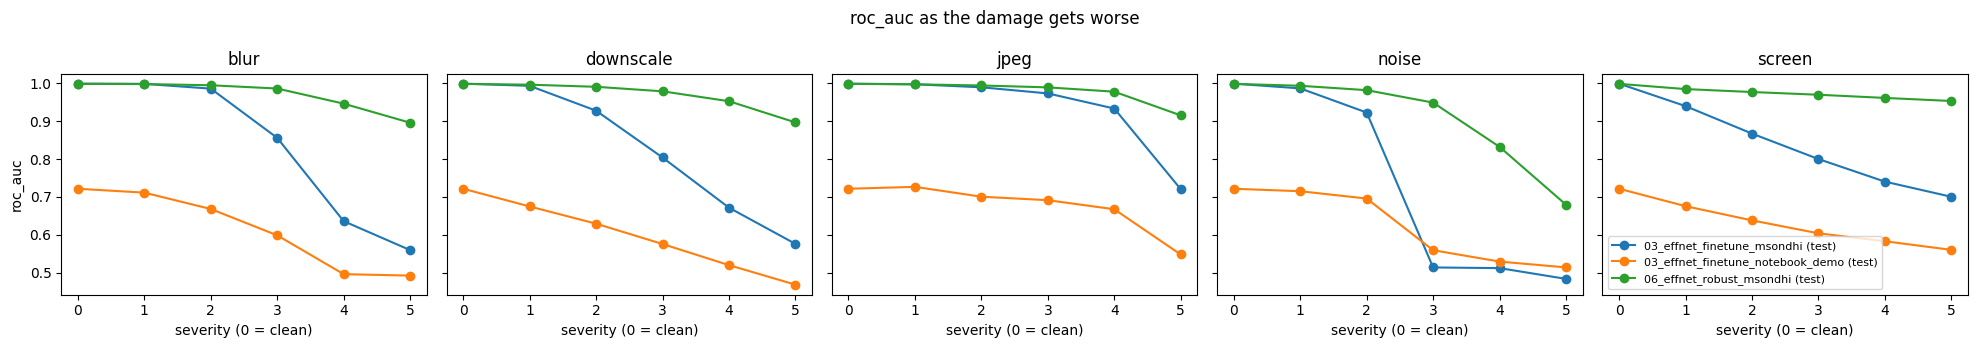

In [7]:
metric = "roc_auc"    # try "accuracy", "far" or "frr"

if not results.empty and (results["condition"] != "clean").any():
    damage_names = sorted(results.loc[results["condition"] != "clean", "condition"].unique())

    fig, axes = plt.subplots(1, len(damage_names), figsize=(4 * len(damage_names), 3.5),
                             sharey=True, squeeze=False)
    for ax, damage in zip(axes[0], damage_names):
        for run in results["run"].unique():
            # this run's rows for this damage, plus its clean row as severity 0
            rows = results[(results["run"] == run) & results["condition"].isin(["clean", damage])]
            rows = rows.sort_values("severity")
            if len(rows) > 1:
                ax.plot(rows["severity"], rows[metric], marker="o", label=run)
        ax.set_title(damage)
        ax.set_xlabel("severity (0 = clean)")
        ax.set_xticks(range(6))
    axes[0, 0].set_ylabel(metric)
    axes[0, -1].legend(fontsize=8)
    fig.suptitle(f"{metric} as the damage gets worse")
    plt.tight_layout()
    plt.show()
else:
    print("Skipped: no damaged-photo results yet.")

## Step 5 — Summary: clean score vs. worst-case score

**What this does:** for each run and each kind of damage, compares the clean score with the score at severity 5,
and shows how much it dropped. This gives numbers you can quote in the report,
e.g. *"blur at severity 5 lowers ROC AUC by 0.12"*.

In [8]:
if not results.empty and (results["condition"] != "clean").any():
    summary_rows = []
    for run in results["run"].unique():
        run_rows = results[results["run"] == run]
        clean_rows = run_rows[run_rows["condition"] == "clean"]
        if clean_rows.empty:
            continue
        clean_score = clean_rows[metric].iloc[0]
        for damage in sorted(run_rows.loc[run_rows["condition"] != "clean", "condition"].unique()):
            damage_rows = run_rows[run_rows["condition"] == damage]
            worst = damage_rows.loc[damage_rows["severity"].idxmax()]   # highest severity tested
            summary_rows.append({
                "run": run,
                "damage": damage,
                f"clean {metric}": clean_score,
                f"{metric} at severity {int(worst['severity'])}": worst[metric],
                "change": worst[metric] - clean_score,
            })
    display(pd.DataFrame(summary_rows).round(3))
else:
    print("Skipped: no damaged-photo results yet.")

,run,damage,clean roc_auc,roc_auc at severity 5,change
0,03_effnet_finetune_msondhi (test),blur,0.999,0.559,-0.440
1,03_effnet_finetune_msondhi (test),downscale,0.999,0.576,-0.424
2,03_effnet_finetune_msondhi (test),jpeg,0.999,0.721,-0.279
3,03_effnet_finetune_msondhi (test),noise,0.999,0.483,-0.516
4,03_effnet_finetune_msondhi (test),screen,0.999,0.700,-0.299
5,03_effnet_finetune_notebook_demo (test),blur,0.722,0.492,-0.230
6,03_effnet_finetune_notebook_demo (test),downscale,0.722,0.468,-0.254
7,03_effnet_finetune_notebook_demo (test),jpeg,0.722,0.548,-0.174
8,03_effnet_finetune_notebook_demo (test),noise,0.722,0.514,-0.208
9,03_effnet_finetune_notebook_demo (test),screen,0.722,0.560,-0.162


## Step 6 — One overall score per model (clean + damaged mix)

**What this does:** gives each model one score for each column, matching how it was tested:

- Model tested on **clean + damaged** photos (E3 and E6 by default, plus any model you scored with
  `INCLUDE_DAMAGE = True` in Step 1b): the **average** over all its
  26 tests (1 clean + 5 kinds of damage × 5 severities). This is like scoring it on a test set where
  photos come in every quality, from perfect to badly damaged.
- Model tested on **clean photos only**: its clean score.

The `tested on` column says which one you are looking at. Only compare models that have the same `tested on` value:
an average that includes damaged photos is naturally lower than a clean-only score.

In [9]:
if not results.empty:
    overall_rows = []
    for run in results["run"].unique():
        run_rows = results[results["run"] == run]
        has_damage = (run_rows["condition"] != "clean").any()
        overall_rows.append({
            "run": run,
            "trained on": run_rows["trained_on"].iloc[0],
            "tested on": f"clean + damaged ({len(run_rows)} tests)" if has_damage else "clean only (1 test)",
            "accuracy": run_rows["accuracy"].mean(),   # mean = average over all tests of this run
            "roc_auc": run_rows["roc_auc"].mean(),
            "far": run_rows["far"].mean(),
            "frr": run_rows["frr"].mean(),
        })
    overall = pd.DataFrame(overall_rows).sort_values("roc_auc", ascending=False)
    display(overall.round(3))
else:
    print("Skipped: no results loaded.")

,run,trained on,tested on,accuracy,roc_auc,far,frr
5,05_resnet50_finetune_msondhi (test),clean photos only,clean only (1 test),0.991,0.999,0.009,0.009
4,04_effnet_gradual_msondhi (test),clean photos only,clean only (1 test),0.982,0.999,0.023,0.012
6,06_effnet_robust_msondhi (test),clean + damaged photos,clean + damaged (26 tests),0.901,0.954,0.086,0.113
0,02_effnet_frozen_msondhi (test),clean photos only,clean only (1 test),0.783,0.862,0.228,0.207
2,03_effnet_finetune_msondhi (test),clean photos only,clean + damaged (26 tests),0.734,0.811,0.313,0.218
3,03_effnet_finetune_notebook_demo (test),clean photos only,clean + damaged (26 tests),0.577,0.614,0.328,0.518
1,02_effnet_frozen_notebook_demo (test),clean photos only,clean only (1 test),0.542,0.547,0.417,0.498


## Next

Notebook **04_error_analysis** opens one trained model, finds the photos it got wrong,
and shows heatmaps (Grad-CAM) of where the model was looking.

## Quick notes to remember

- These numbers come from the **test** set. Use them only for the final comparison, not to tune settings.
- `far` matters most for fraud (fakes getting through); `frr` matters most for customer experience.
- A run tested on clean photos only appears in Steps 3 and 6 but not in Steps 4–5.
- Which models train on damaged photos is set in the config: `augment.degradation: false` in `configs/base.yaml`,
  so `01`–`05` and the E7 runs (`07_effnet_n…`, E3 with fewer training photos) train on clean photos only.
  `06_effnet_robust` (E6) turns it on: robust training.
- The key robustness figure is the Step 4 chart of **E3 (standard) vs. E6 (robust training)**; both are
  tested on damaged photos by default (Step 1b).
- Files made here (new score files): on Kaggle they are kept only when you click **Save Version**; on Colab
  they are saved straight into your Drive.